# GPU compute prices: what is the physical world doing?

A dashboard for Ornn's GPU price indices. It answers, for today and for all six GPUs: **is the physical world moving GPU prices, and how?**

**How to use it:** *Run All*. Data older than 24 hours is downloaded again, so every run reflects the latest Ornn, Census and Yahoo Finance data. Set `REFRESH = True` to force a full download, or `ASOF` to see the dashboard as it looked on a past date (only data available on that date is used).

**The short answer so far:** GPU prices are set by **scarcity**. They stay roughly flat until a GPU's utilization passes ~85%, then rise sharply. The physical world matters through **how much capacity gets built** (data-center construction, memory supply), not through input costs: energy prices show no lasting link for any GPU. The research behind this is in `explore.ipynb` and `FINDINGS.md`.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ornn_analysis import dashboard as D
from ornn_analysis import signals
from ornn_analysis.daily import compute, summary

REFRESH = False   # True = download everything again
ASOF = None       # e.g. "2026-03-06" to see a past date; None = latest data

pd.set_option("display.max_colwidth", 120)
data, failures = D.load(refresh=REFRESH)
asof = pd.Timestamp(ASOF) if ASOF else D.latest_date(data)
energy = D.energy_by_gpu(data, asof)          # the energy check for every GPU (takes ~20 seconds)
display(Markdown(f"**Data as of {asof:%d %B %Y}.**" + (f" Sources that failed to load: {failures}" if failures else "")))

**Data as of 30 October 2026.**

## 1 · Today at a glance

In [3]:
for line in summary(compute(data, asof), quality_section="section 7"):
    display(Markdown("- " + line))

- The market is full: all 6 GPUs have 8-13% spare capacity. This is the zone where prices have jumped before.

- Data-center construction is accelerating (+73% vs a year earlier). If the past pattern holds, the market should loosen in the coming months.

- Memory prices are still rising: DDR5 spot $61.33 (+6% in 30 days, +318% in a year). An H200 costs 2.0x an H100 (same chip, more memory), up from 1.8x three months ago.

- Oil and gas: no lasting link to GPU prices.

- 4 data-quality notes to review (section 7).

Each physical input: what it is doing now, how strong the evidence is that it moves GPU prices, and which way it is pushing. **Route** is how it would reach prices: through scarcity, through how much capacity exists, or through operating cost.

In [4]:
D.inputs_table(data, asof, energy)

,Route,Now,Evidence it moves GPU prices,Pressure now
Input,,,,
Utilization (scarcity),Scarcity,6 of 6 GPUs full (85%+ used),"Strong: price jumps came after utilization passed ~85% for all 6 GPUs, on the way up and down (2026)",Up
Data-center construction (Census),Capacity,"+73% vs a year earlier (Aug 2026), accelerating","Medium-low: slower construction was followed by a tighter market 6-9 months later, for all 6 GPUs; one cycle observed","Easing, months ahead"
Memory: DDR5 spot (Ornn),Capacity,"$61.33, +6% in 30 days, +319% in a year",Low-medium: the shortage started Oct 2025 as utilization began rising; memory-heavy GPUs rose most; no week-to-week ...,"Up, slowly"
WTI oil,Cost (power),"$102.90, +15% in 30 days",No lasting link for any GPU (one-off episode for H100 SXM); power is ~3-5% of a GPU-hour,None detected
Brent oil,Cost (power),"$111.46, +9% in 30 days",No lasting link for any GPU (one-off episode for H100 SXM); power is ~3-5% of a GPU-hour,None detected
US natural gas,Cost (power),"$2.90, -4% in 30 days",No lasting link for any GPU (one-off episode for B200); power is ~3-5% of a GPU-hour,None detected


## 2 · How full is each GPU market?
The main signal. Utilization is the share of Ornn's tracked capacity that is rented, averaged over 7 days (demand peaks mid-week and drops at weekends). **Full** = 85%+ used, where prices have jumped before. **Filling up** = 75-85% and up 3+ points in 4 weeks, the early warning. **Busy** = 75-85%. **Room available** = under 75%.

In [5]:
D.gpu_table(data, asof)

,Price ($/hr),"Price, 7 days","Price, 30 days",Utilization (7-day avg),"Change, 4 weeks",Status,Price pressure
H100 SXM,2.96,-7%,+9%,92%,+12 pts,Full,Up
H200,5.56,-3%,-0%,87%,+4 pts,Full,Up
B200,9.89,+3%,+22%,87%,-6 pts,Full,Up
A100 SXM4,1.11,+2%,+26%,88%,+16 pts,Full,Up
RTX 5090,0.72,-6%,+14%,88%,+10 pts,Full,Up
RTX PRO 6000 WS,1.55,+1%,+5%,89%,+10 pts,Full,Up


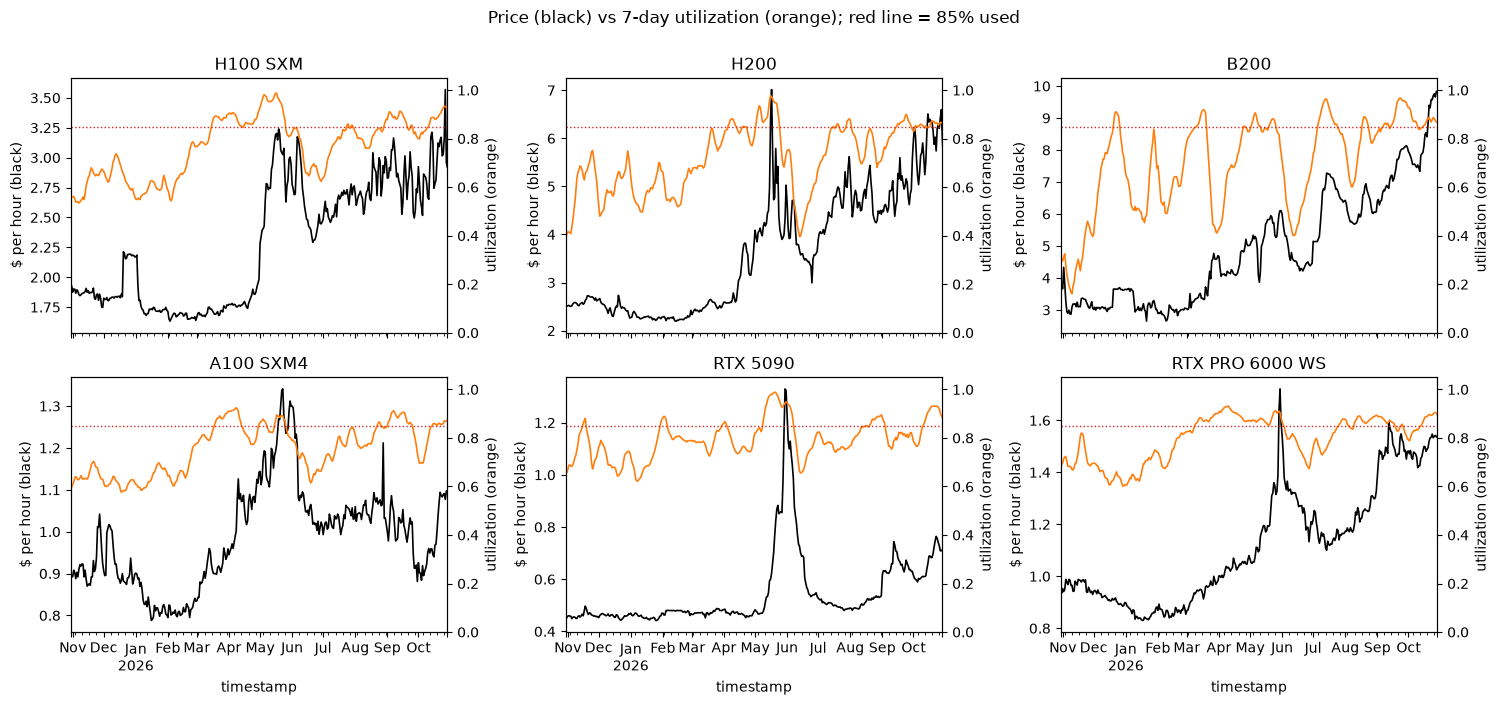

In [6]:
D.plot_scarcity(data, asof); plt.show()

## 3 · Supply: data-center construction
Census monthly spending on US data-center construction (the value of building work done that month). Facilities come online months after they're built, so construction growth has led utilization: when construction slowed in 2025, the market tightened 6-9 months later, for all six GPUs. This rests on one cycle, so it's a pattern to watch, not a forecast to rely on.

**Latest month: August 2026** — building at $85bn a year, +73% vs a year earlier (three months before: +36%). Construction is **accelerating**.

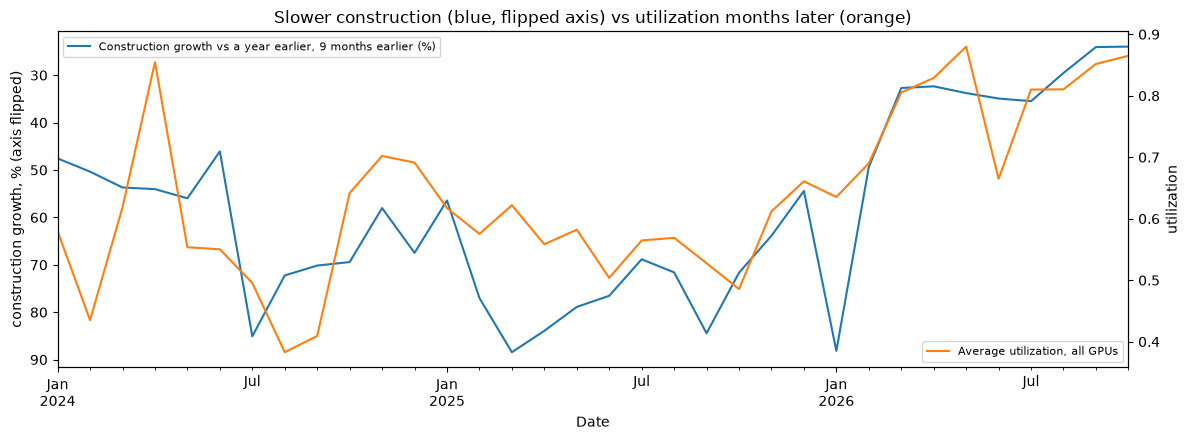

In [7]:
s = signals.supply_pipeline(data["construction"], asof)
display(Markdown(f"**Latest month: {pd.Timestamp(s['latest_month'] + '-01'):%B %Y}** — building at ${s['spending_bn_annual_rate']:.0f}bn a year, "
                 f"{s['growth_yoy_%']:+.0f}% vs a year earlier (three months before: {s['growth_yoy_3m_ago_%']:+.0f}%). Construction is **{s['direction']}**."))
D.plot_supply(data, asof); plt.show()

## 4 · Memory
Memory is the other capacity constraint: the HBM on GPUs is made on the same production lines as regular DRAM. Ornn's DDR5 spot price (commodity DRAM, not HBM itself) shows the shortage, which started in October 2025, the same month utilization began rising. The H200 is an H100 with more memory, so the H200/H100 price ratio shows what the market pays for memory: it rose months after DRAM prices did. Memory moves slowly, through capacity; week-to-week DDR5 moves don't lead GPU prices.

,Price ($),30 days (%),90 days (%),1 year (%)
DDR5 16Gb chip,61.33,6.1,20.3,318.5
DDR5 server module (RDIMM 32GB),2165.0,0.1,39.2,NaN


H200 costs **2.02x** an H100 (+10% over 90 days); RTX PRO 6000 costs **2.12x** an RTX 5090 (-10%).

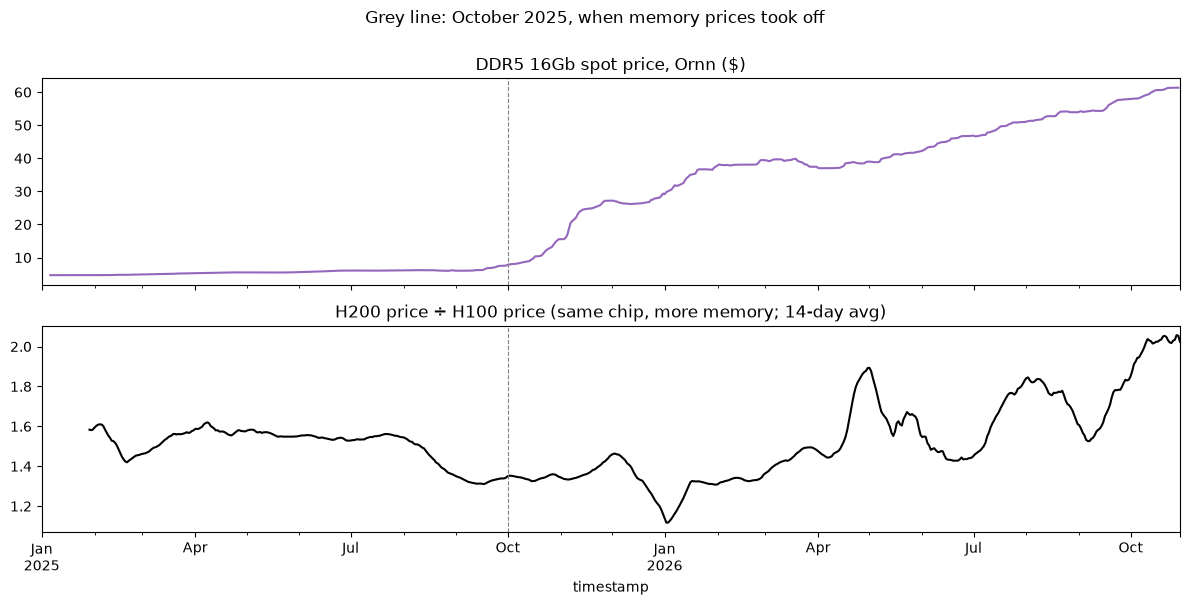

In [8]:
m = signals.memory(data["prices"], data["memory"], asof)
spot = pd.DataFrame(m["spot"]).T[["price", "change_30d_%", "change_90d_%", "change_1y_%"]]
spot.columns = ["Price ($)", "30 days (%)", "90 days (%)", "1 year (%)"]
display(spot)
display(Markdown(f"H200 costs **{m['premium_H200/H100']:.2f}x** an H100 ({m['premium_H200/H100_90d_change_%']:+.0f}% over 90 days); "
                 f"RTX PRO 6000 costs **{m['premium_RTXPRO6000/RTX5090']:.2f}x** an RTX 5090 ({m['premium_RTXPRO6000/RTX5090_90d_change_%']:+.0f}%)."))
D.plot_memory(data, asof); plt.show()

## 5 · Energy: do oil or gas prices move GPU prices?
For each GPU and each energy price, the check looks at weekly price changes over the last two years, with the energy price 0-12 weeks earlier. A real link must **beat chance** (fewer than 5% of randomly shifted copies match it) **and show up in both years**.

- **no signal**: could easily be chance.
- **one period only**: beats chance, but only because of one episode (for H100 and oil: the 2026 Strait of Hormuz shock followed by the spring GPU squeeze).
- **possible signal - check**: beats chance in both years. None so far.

This also fits the cost arithmetic: power is about 7-10 cents of a $2-3 GPU-hour.

In [9]:
energy.pivot(index="GPU", columns="Input", values="Verdict")

Input,Brent oil,US natural gas,WTI oil
GPU,,,
A100 SXM4,no signal,no signal,no signal
B200,no signal,one period only,no signal
H100 SXM,one period only,no signal,one period only
H200,no signal,no signal,no signal
RTX 5090,no signal,no signal,no signal
RTX PRO 6000 WS,no signal,no signal,no signal


In [10]:
energy.set_index(["GPU", "Input"]).round(2)

Strongest lead (weeks)  Correlation  \
GPU             Input                                                 
H100 SXM        WTI oil                              9         0.46   
                Brent oil                            9         0.44   
                US natural gas                       2        -0.16   
H200            WTI oil                              0         0.28   
                Brent oil                            0         0.26   
                US natural gas                       9        -0.09   
B200            WTI oil                             12        -0.28   
                Brent oil                           12        -0.29   
                US natural gas                       9         0.33   
A100 SXM4       WTI oil                              1         0.27   
                Brent oil                            1         0.25   
                US natural gas                      12        -0.20   
RTX 5090        WTI oil                             11         0.23   
                Brent oil                           10         0.31   
                US natural gas                       7        -0.10   
RTX PRO 6000 WS WTI oil                              2         0.30   
                Brent oil                           10         0.30   
                US natural gas                       3        -0.13   

                                Older year  Latest year  Chance %  \
GPU             Input                                               
H100 SXM        WTI oil               0.22         0.51       0.0   
                Brent oil             0.21         0.48       0.0   
                US natural gas       -0.07        -0.19      83.3   
H200            WTI oil              -0.03         0.31       9.7   
                Brent oil            -0.00         0.29      13.3   
                US natural gas        0.01        -0.12     100.0   
B200            WTI oil              -0.35        -0.37      36.7   
                Brent oil            -0.37        -0.36       9.0   
                US natural gas        0.44         0.13       3.7   
A100 SXM4       WTI oil               0.16         0.40      10.7   
                Brent oil             0.21         0.31      21.7   
                US natural gas       -0.12        -0.27      52.0   
RTX 5090        WTI oil               0.05         0.24      40.7   
                Brent oil             0.02         0.35       6.3   
                US natural gas       -0.02        -0.11     100.0   
RTX PRO 6000 WS WTI oil               0.30         0.34       5.3   
                Brent oil             0.35         0.28      21.0   
                US natural gas       -0.25        -0.13      99.3   

                                        Verdict  
GPU             Input                            
H100 SXM        WTI oil         one period only  
                Brent oil       one period only  
                US natural gas        no signal  
H200            WTI oil               no signal  
                Brent oil             no signal  
                US natural gas        no signal  
B200            WTI oil               no signal  
                Brent oil             no signal  
                US natural gas  one period only  
A100 SXM4       WTI oil               no signal  
                Brent oil             no signal  
                US natural gas        no signal  
RTX 5090        WTI oil               no signal  
                Brent oil             no signal  
                US natural gas        no signal  
RTX PRO 6000 WS WTI oil               no signal  
                Brent oil             no signal  
                US natural gas        no signal

## 6 · Each GPU is its own market
Most of the deeper research was done on the H100, so it matters how far it speaks for the others. Week to week, GPU prices move together only weakly, and over the period they went in different directions (newer, memory-heavy GPUs up; older and consumer GPUs flat or down). The common driver across all six is supply and demand through utilization; chip generation, memory size and customer mix explain much of the rest.

Average week-to-week correlation between GPUs since all six were trading: **0.17 for prices**, **0.28 for utilization** (1 = always move together, 0 = unrelated).

,H100 SXM,H200,B200,A100 SXM4,RTX 5090,RTX PRO 6000 WS
H100 SXM,1.00,0.23,0.34,0.22,0.19,0.15
H200,0.23,1.00,0.16,-0.07,0.06,-0.19
B200,0.34,0.16,1.00,0.14,0.22,0.15
A100 SXM4,0.22,-0.07,0.14,1.00,0.28,0.11
RTX 5090,0.19,0.06,0.22,0.28,1.00,0.63
RTX PRO 6000 WS,0.15,-0.19,0.15,0.11,0.63,1.00


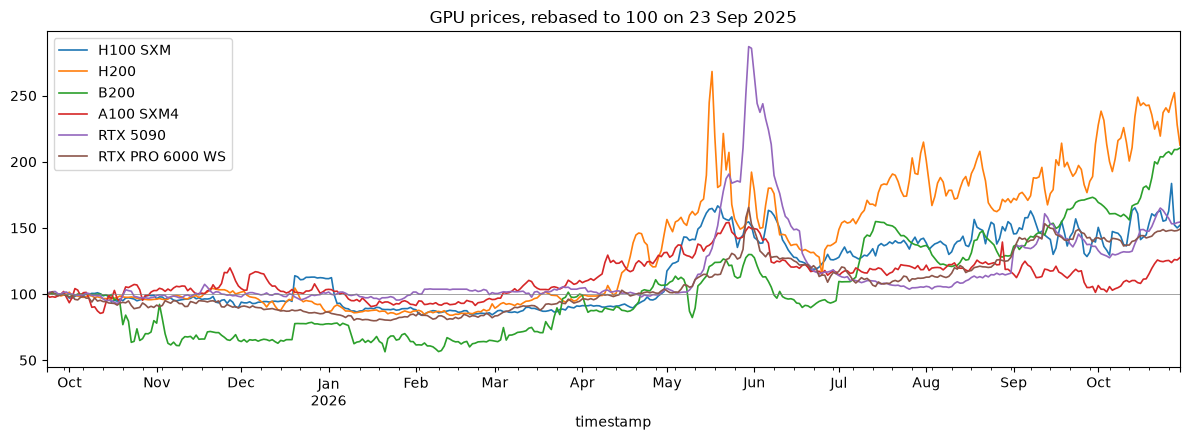

In [11]:
pc, uc, avg_p, avg_u = D.gpu_correlations(data, asof)
display(Markdown(f"Average week-to-week correlation between GPUs since all six were trading: **{avg_p:.2f} for prices**, **{avg_u:.2f} for utilization** "
                 "(1 = always move together, 0 = unrelated)."))
display(pc)
D.plot_gpu_prices(data, asof); plt.show()

## 7 · Data quality
Large price moves that utilization doesn't explain, and feeds that stopped updating. Two past moves in the H100 index (August 2024, December 2025) reversed within days while utilization didn't move, so they look like index artifacts. Similar moves are listed here for review; real moves in a full market can look the same.

In [12]:
notes = signals.data_quality(data["prices"], data["util"], asof)
display(Markdown("\n".join(f"- {n}" for n in notes) if notes else "Nothing to flag."))

- H100 SXM: price -17% in 3 days (to 30 Oct) while utilization moved +1.0 points. Too recent to tell if it holds.
- H200: price +26% in 3 days (to 2 Oct) while utilization moved -5.9 points. It has since reversed.
- H200: price -17% in 3 days (to 6 Oct) while utilization moved +0.0 points. It has since reversed.
- H200: price +24% in 3 days (to 15 Oct) while utilization moved -1.4 points. It has held so far.